# Dataset Review 2/3 — NASA C-MAPSS (Turbofan Engine Degradation)

**Purpose.** Evidence-based evaluation of the C-MAPSS dataset as a candidate for a thesis on
causal AI in predictive maintenance, following the workflow:

> Causal Discovery → Root Cause Analysis → Interventions → Counterfactual XAI → Actionable Recommendations

**Dataset.** Saxena, A. & Goebel, K. (2008). *Turbofan Engine Degradation Simulation Data Set*,
NASA Ames Prognostics Data Repository (PCoE data set #6), Moffett Field, CA. Public domain.
Companion paper: Saxena, Goebel, Simon & Eklund (2008), "Damage Propagation Modeling for
Aircraft Engine Run-to-Failure Simulation", *PHM08* (included as PDF in the download).

**What it is.** Run-to-failure trajectories of a simulated turbofan engine fleet produced with
NASA's C-MAPSS thermodynamic simulator. Four subsets (FD001–FD004) vary the number of operating
conditions (1 or 6) and fault modes (HPC degradation, fan degradation). Per cycle: 3 operational
settings + 21 physically meaningful sensor channels. The de-facto standard PdM/RUL benchmark
since 2008, with hundreds of published baselines.

**Review questions:** documentation completeness · data cleanliness · preprocessing effort ·
intervention support · temporal resolution for PCMCI.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

sys.path.insert(0, str(Path.cwd().parent / "src"))
from causalpdm import cmapss
from causalpdm.config import CMAPSS_RAW

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

## 1. Dataset inventory

Four subsets of increasing difficulty; each has train (run-to-failure), test (truncated) and a
true-RUL file for the test engines.

In [2]:
inventory = []
for sub in cmapss.SUBSETS:
    tr, te, rul = cmapss.load_train(sub), cmapss.load_test(sub), cmapss.load_rul(sub)
    inventory.append({
        "subset": sub,
        "train_engines": tr["unit"].nunique(),
        "test_engines": te["unit"].nunique(),
        "train_rows": len(tr),
        "median_train_len": int(tr.groupby("unit")["cycle"].max().median()),
        "max_train_len": int(tr.groupby("unit")["cycle"].max().max()),
        "operating_conditions": tr[cmapss.SETTING_COLS].round({"setting_1": 0, "setting_2": 2, "setting_3": 0}).drop_duplicates().shape[0],
    })
pd.DataFrame(inventory)

,subset,train_engines,test_engines,train_rows,median_train_len,max_train_len,operating_conditions
0,FD001,100,100,20631,199,362,1
1,FD002,260,259,53759,199,378,6
2,FD003,100,100,24720,220,525,1
3,FD004,249,248,61249,234,543,6


In [3]:
total_mb = sum(f.stat().st_size for f in CMAPSS_RAW.glob("*.txt")) / 1e6
print(f"Total size on disk: {total_mb:.0f} MB — trivially portable")
print("Sensor channels are physically documented, e.g.:")
for k in list(cmapss.SENSOR_DESCRIPTIONS)[:5]:
    print(f"  {k}: {cmapss.SENSOR_DESCRIPTIONS[k]}")

Total size on disk: 45 MB — trivially portable
Sensor channels are physically documented, e.g.:
  s_1: Total temperature at fan inlet (T2, degR)
  s_2: Total temperature at LPC outlet (T24, degR)
  s_3: Total temperature at HPC outlet (T30, degR)
  s_4: Total temperature at LPT outlet (T50, degR)
  s_5: Pressure at fan inlet (P2, psia)


## 2. General EDA

We focus on **FD001** (single operating condition — the cleanest causal setting) and use FD002
to illustrate the operating-regime structure.

### 2.1 Cleanliness and structure

In [4]:
train = cmapss.load_train("FD001")
print(f"Shape: {train.shape} | engines: {train['unit'].nunique()}")
print(f"Missing values: {int(train.isna().sum().sum())}")
print(f"Duplicated rows: {int(train.duplicated().sum())}")
gaps = train.groupby("unit")["cycle"].apply(lambda s: (s.diff().dropna() != 1).sum()).sum()
print(f"Gaps in cycle index across all engines: {int(gaps)} -> perfectly regular sampling")
train.head()

Shape: (20631, 27) | engines: 100
Missing values: 0
Duplicated rows: 0
Gaps in cycle index across all engines: 0 -> perfectly regular sampling


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [5]:
# Constant channels carry no causal information and are dropped in preprocessing.
stds = train[cmapss.SENSOR_COLS].std()
constant = stds[stds < 1e-6].index.tolist()
informative = [s for s in cmapss.SENSOR_COLS if s not in constant]
print(f"Constant sensors in FD001: {constant} ({len(constant)}/21)")
print(f"Informative sensors: {len(informative)}")

Constant sensors in FD001: ['s_1', 's_5', 's_10', 's_16', 's_18', 's_19'] (6/21)
Informative sensors: 15


### 2.2 Trajectory lengths and degradation behaviour

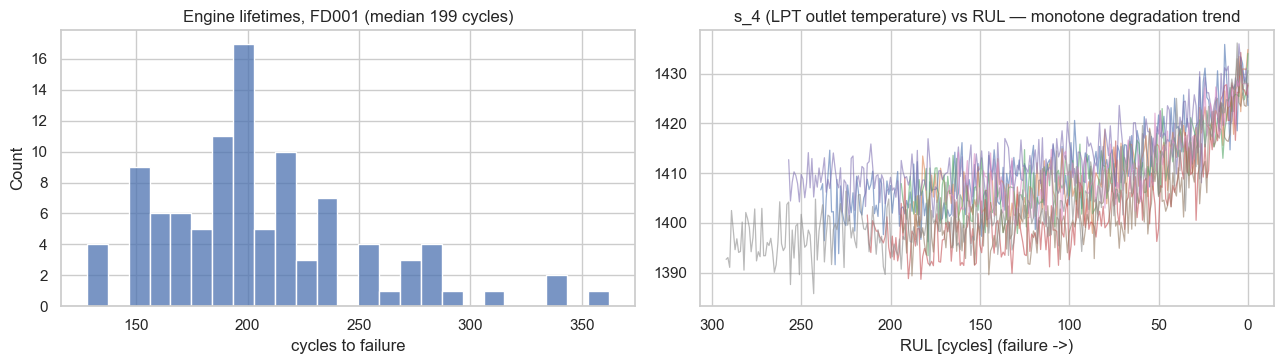

In [6]:
lifetimes = train.groupby("unit")["cycle"].max()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(lifetimes, bins=25, ax=axes[0])
axes[0].set_title(f"Engine lifetimes, FD001 (median {lifetimes.median():.0f} cycles)")
axes[0].set_xlabel("cycles to failure")

for u in lifetimes.sample(8, random_state=1).index:
    d = train[train["unit"] == u]
    axes[1].plot(d["rul"], d["s_4"], alpha=0.6, lw=0.9)
axes[1].invert_xaxis()
axes[1].set_xlabel("RUL [cycles] (failure ->)")
axes[1].set_title("s_4 (LPT outlet temperature) vs RUL — monotone degradation trend")
plt.tight_layout(); plt.show()

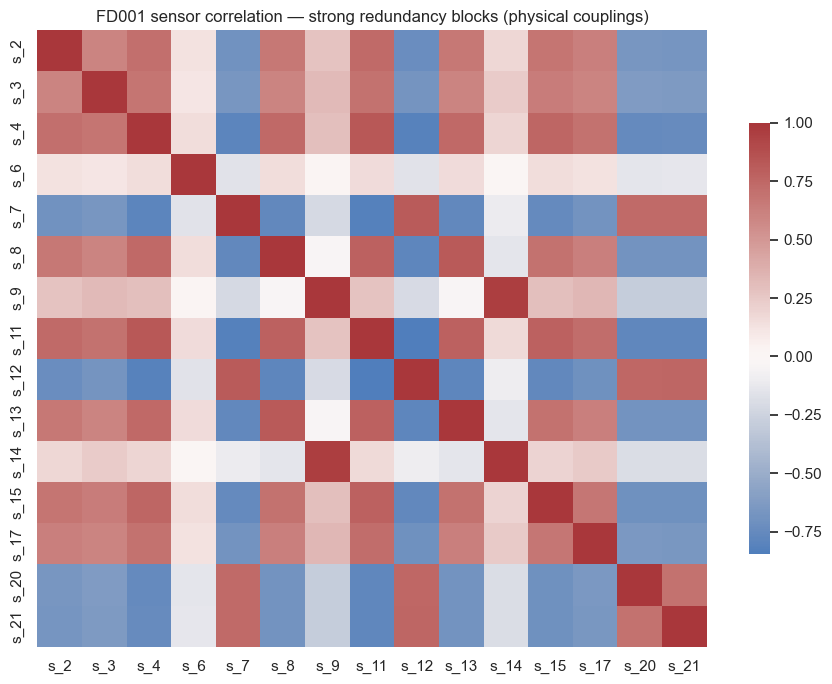

In [7]:
# Correlation structure of informative sensors (fleet-pooled)
corr = train[informative].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("FD001 sensor correlation — strong redundancy blocks (physical couplings)")
plt.tight_layout(); plt.show()

### 2.3 Operating regimes (FD002/FD004)

Six discrete flight conditions dominate the raw signal variance in FD002/FD004. For causal
analysis these act as a known *context variable* — either condition on the regime or restrict
to FD001/FD003.

FD002 distinct operating regimes: 6


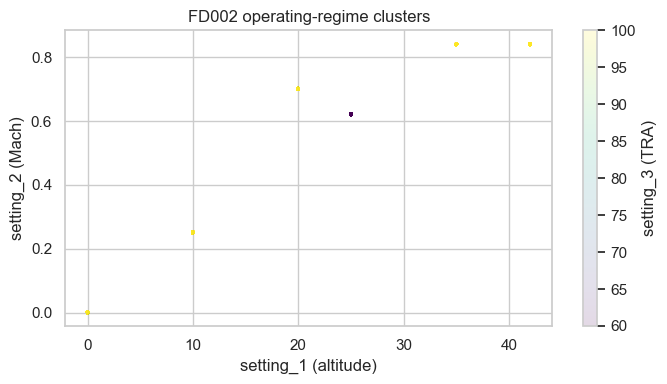

In [8]:
tr2 = cmapss.load_train("FD002")
# Settings carry small measurement noise; rounding to physical precision recovers the regimes.
regimes = tr2[cmapss.SETTING_COLS].round({"setting_1": 0, "setting_2": 2, "setting_3": 0}).drop_duplicates()
print(f"FD002 distinct operating regimes: {len(regimes)}")
fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(tr2["setting_1"], tr2["setting_2"], s=2, alpha=0.15,
                c=tr2["setting_3"], cmap="viridis")
ax.set_xlabel("setting_1 (altitude)"); ax.set_ylabel("setting_2 (Mach)")
ax.set_title("FD002 operating-regime clusters")
plt.colorbar(sc, label="setting_3 (TRA)")
plt.tight_layout(); plt.show()

## 3. Focused EDA — suitability for the causal workflow

### 3.1 Causal Discovery

There is **no ground-truth causal graph**: NASA released the simulator outputs, not the
simulator's internal dependency structure. The engine physics in the PHM08 paper allow a
*plausible* physics-informed graph, but discovered graphs cannot be scored objectively.

**PCMCI readiness**, on the other hand, is excellent: perfectly regular cycle-based sampling,
all-continuous variables, and per-engine series of 128–362 cycles.

In [9]:
# Stationarity: PCMCI assumes (approximate) stationarity. Degradation is a trend by design,
# so we test raw vs first-differenced signals per engine (ADF test, alpha = 0.05).
sample_units = lifetimes.sample(20, random_state=0).index
rows = []
for s in ["s_2", "s_4", "s_7", "s_11", "s_12"]:
    raw_p, diff_p = [], []
    for u in sample_units:
        x = train.loc[train["unit"] == u, s].to_numpy()
        raw_p.append(adfuller(x)[1])
        diff_p.append(adfuller(np.diff(x))[1])
    rows.append({
        "sensor": s,
        "stationary_raw_%": 100 * np.mean(np.array(raw_p) < 0.05),
        "stationary_diff_%": 100 * np.mean(np.array(diff_p) < 0.05),
    })
pd.DataFrame(rows).round(0)

,sensor,stationary_raw_%,stationary_diff_%
0,s_2,0.0,100.0
1,s_4,0.0,100.0
2,s_7,0.0,100.0
3,s_11,0.0,100.0
4,s_12,0.0,100.0


**Reading.** Raw signals are non-stationary for many engines (the degradation trend — expected),
first differences are stationary essentially everywhere. Standard practice for PCMCI on C-MAPSS:
difference or detrend per unit, then pool engines as independent realisations. The degradation
state itself acts as a slowly-moving **latent confounder** driving all sensors — a modelling
challenge to address explicitly (e.g. include RUL/health proxy as a variable, or use LPCMCI).

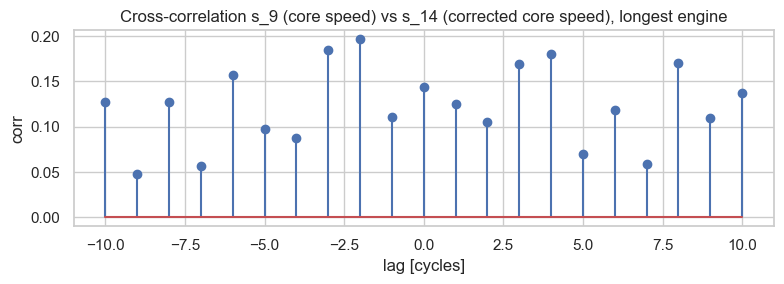

In [10]:
# Lagged dependence exists for PCMCI to find: cross-correlation between sensors at lag 0..10
from scipy.signal import correlate
u = lifetimes.idxmax()
d = train[train["unit"] == u]
x = (d["s_9"] - d["s_9"].mean()).to_numpy()
y = (d["s_14"] - d["s_14"].mean()).to_numpy()
lags = np.arange(-10, 11)
cc = [np.corrcoef(x[max(0,-l):len(x)-max(0,l)], y[max(0,l):len(y)-max(0,-l)])[0,1] for l in lags]
fig, ax = plt.subplots(figsize=(8, 3))
ax.stem(lags, cc)
ax.set_xlabel("lag [cycles]"); ax.set_ylabel("corr")
ax.set_title("Cross-correlation s_9 (core speed) vs s_14 (corrected core speed), longest engine")
plt.tight_layout(); plt.show()

### 3.2 Root Cause Analysis

Fault labels exist only at **subset level** (FD001: HPC degradation; FD003: HPC *or* fan
degradation — but individual engines are not labelled with which). There is no per-run causing
variable and no diagnosis label ⇒ RCA can only be evaluated *qualitatively* (does the method
point at HPC-related sensors?).

In [11]:
# Qualitative check: which sensors separate late-life from early-life the most (effect size)?
early = train[train["rul"] > 200][informative].mean()
late = train[train["rul"] < 20][informative].mean()
effect = ((late - early) / train[informative].std()).sort_values(key=np.abs, ascending=False)
effect.head(8).to_frame("standardised shift (late vs early life)").round(2)

,standardised shift (late vs early life)
s_11,2.66
s_4,2.59
s_12,-2.56
s_7,-2.50
s_15,2.46
s_21,-2.43
s_20,-2.38
s_2,2.32


### 3.3 Interventions

**None.** The data is purely observational (simulated flights). No variable is ever set by an
experimenter; operating-condition changes in FD002/FD004 are regime shifts, not controlled
do-interventions, and they affect all variables simultaneously. Intervention analysis on
C-MAPSS is therefore *model-based only* (estimate an SCM, then simulate do()) — it can never be
validated against held-out interventional data.

### 3.4 Counterfactual XAI

Same asymmetry: counterfactuals can be *generated* (fit SCM → abduction/action/prediction) and
are popular on C-MAPSS in the XAI literature, but there is no ground truth to check them
against. The underlying simulator would be the perfect oracle — but NASA has not released it
for arbitrary re-simulation of individual trajectories.

### 3.5 Actionable recommendations / dashboard suitability

Sensors are physically meaningful (temperatures, pressures, speeds), RUL is an operationally
meaningful KPI, and the dataset is small and static — ideal for a demo dashboard. Ecosystem
maturity is unmatched: hundreds of published baselines to compare against.

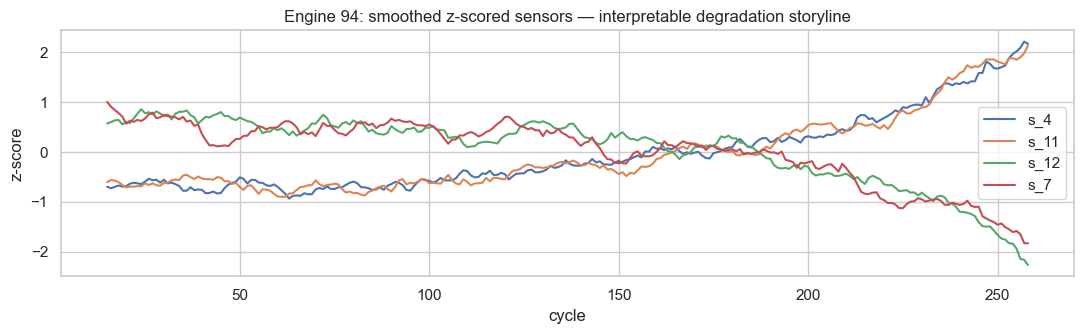

In [12]:
# Dashboard-style health view: normalised key sensors for one engine against cycle
u = int(lifetimes.sample(1, random_state=3).index[0])
d = train[train["unit"] == u].set_index("cycle")
z = (d[["s_4", "s_11", "s_12", "s_7"]] - d[["s_4", "s_11", "s_12", "s_7"]].mean()) / d[["s_4", "s_11", "s_12", "s_7"]].std()
ax = z.rolling(15).mean().plot(figsize=(11, 3.5))
ax.set_title(f"Engine {u}: smoothed z-scored sensors — interpretable degradation storyline")
ax.set_ylabel("z-score")
plt.tight_layout(); plt.show()

## 4. Verdict — C-MAPSS

| Workflow stage | Support | Evidence |
|---|---|---|
| Causal discovery | **Runnable, not benchmarkable** | Perfect PCMCI input format (regular, continuous, T≈130–360/engine, poolable) but no ground-truth graph to score against |
| Root cause analysis | **Weak** | Fault mode known only at subset level; no per-engine cause or diagnosis labels |
| Interventions | **None** | Purely observational; do() only via fitted models, unverifiable |
| Counterfactual XAI | **Generate yes, validate no** | No simulator access, no twin runs |
| Actionable recommendations | **Good** | Physically named sensors, RUL KPI, mature baseline ecosystem |

**Caveats to carry into the thesis proposal**
1. Zero preprocessing risk (no missing values, no gaps) and excellent documentation — the lowest-friction dataset of the three.
2. Simulated data: fleet-level variation comes from seeded initial wear; results may flatter methods relative to real machinery.
3. The degradation trend is a latent confounder for causal discovery — must be handled explicitly (differencing/detrending shown above).
4. Strong sensor redundancy (correlation blocks) will produce dense/unstable graphs unless dimensionality is reduced.
5. Best role: *methodological sandbox and comparability anchor* — not a dataset on which causal claims can be validated.